# International Factor Exposure & Return Attribution Lab

Which risks drive the returns of international equity ETFs, and are those risks **global** or **local**?

**Research questions**
1. How much of each ETF's return do Fama–French 5 + momentum factors explain?
2. Integration vs segmentation: do *regional* factors explain returns better than *global* (developed-market) factors?
3. Currency: does exposure to the broad US dollar add explanatory power?
4. Stability: did exposures change after 2016?

**Data**: Kenneth French international factor library (USD, monthly), Yahoo Finance total returns, FRED broad dollar index.
**Method**: OLS with Newey–West (HAC) standard errors, rolling 36-month betas, return attribution, Chow-type Wald stability test.

## 0. Setup (Colab or local)

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/YOUR_USER/intl-factor-lab.git"  # <- set after pushing to GitHub

if "google.colab" in sys.modules and not Path("intl_factors").exists():
    if not Path("intl-factor-lab").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "intl-factor-lab"], check=True)
    os.chdir("intl-factor-lab")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "yfinance", "statsmodels"], check=True)

ROOT = Path.cwd() if Path("intl_factors").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from intl_factors import data, models, plots

pd.set_option("display.float_format", "{:.3f}".format)

## 1. Configuration

In [2]:
ETFS = data.ETFS                 # ticker -> (description, local Ken French region)
GLOBAL_REGION = "Developed"      # benchmark "global" factor set
SINGLE_COUNTRY = ["EWZ"]         # country funds explained by a broader regional factor set
SPLIT = "2016-01"                # subperiod break for the stability test
WINDOW = 36                      # months for rolling betas
FIG_DIR = ROOT / "reports" / "figures"
TAB_DIR = ROOT / "reports" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

pd.DataFrame(ETFS, index=["description", "local region"]).T

,description,local region
EFA,MSCI EAFE (developed ex US & Canada),Developed_ex_US
VGK,FTSE Developed Europe,Europe
EWJ,MSCI Japan,Japan
EPP,MSCI Pacific ex Japan,Asia_Pacific_ex_Japan
EEM,MSCI Emerging Markets,Emerging
EWZ,MSCI Brazil,Emerging


## 2. Data collection
Downloads are cached in `data/cache/`. Set `refresh=True` to pull the latest vintage
(record the date: French factors are revised when Bloomberg data are updated).

In [3]:
rets, factors, usd = data.load_all(ETFS, refresh=False)
print("ETF returns:", rets.index.min(), "->", rets.index.max())
for region, f in factors.items():
    print(f"{region:<24} factors: {f.index.min()} -> {f.index.max()}")
print("USD factor:", usd.index.min(), "->", usd.index.max())

ETF returns: 2005-02 -> 2026-10
Asia_Pacific_ex_Japan    factors: 1990-11 -> 2026-09
Developed                factors: 1990-11 -> 2026-09
Developed_ex_US          factors: 1990-11 -> 2026-09
Emerging                 factors: 1990-01 -> 2026-09
Europe                   factors: 1990-11 -> 2026-09
Japan                    factors: 1990-11 -> 2026-09
USD factor: 2006-02 -> 2026-10


## 3. Cleaning checks and descriptive statistics
- Returns are monthly decimals in USD; ETF returns include reinvested dividends (Yahoo adjusted close).
- No prices are filled before inception or across gaps; the current, incomplete month is dropped.
- The factor correlation matrix checks multicollinearity (high correlations widen beta confidence intervals).

corr(EM Mkt-RF, USD) = -0.78


,first,last,months,missing_inside
EFA,2005-02,2026-10,261,0
VGK,2005-04,2026-10,259,0
EWJ,2005-02,2026-10,261,0
EPP,2005-02,2026-10,261,0
EEM,2005-02,2026-10,261,0
EWZ,2005-02,2026-10,261,0


,ann_return,ann_vol,worst_month,best_month,sharpe_like
EFA,0.074,0.167,-0.208,0.143,0.444
VGK,0.080,0.184,-0.218,0.164,0.433
EWJ,0.064,0.152,-0.156,0.116,0.420
EPP,0.089,0.201,-0.265,0.161,0.441
EEM,0.088,0.210,-0.256,0.169,0.420
EWZ,0.113,0.327,-0.386,0.284,0.344


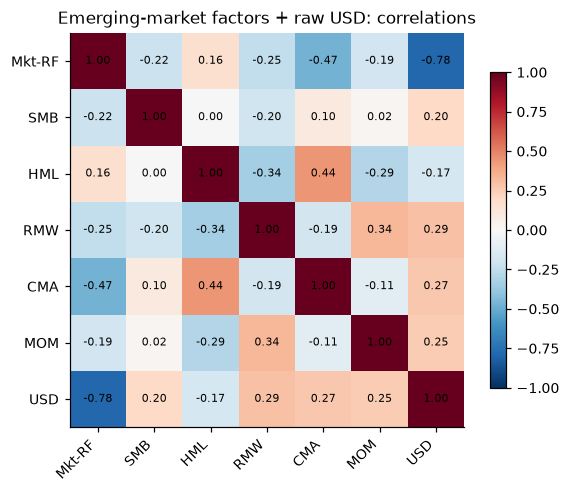

In [4]:
coverage = pd.DataFrame({
    "first": rets.apply(lambda s: s.first_valid_index()),
    "last": rets.apply(lambda s: s.last_valid_index()),
    "months": rets.notna().sum(),
    "missing_inside": rets.apply(lambda s: s.loc[s.first_valid_index():s.last_valid_index()].isna().sum()),
})
assert coverage["missing_inside"].eq(0).all(), "gap inside an ETF's history"
display(coverage)

stats = pd.DataFrame({
    "ann_return": rets.mean() * 12,
    "ann_vol": rets.std() * np.sqrt(12),
    "worst_month": rets.min(),
    "best_month": rets.max(),
})
stats["sharpe_like"] = stats["ann_return"] / stats["ann_vol"]
display(stats)

em = models.align(rets["EEM"], factors["Emerging"], usd, orthogonalize_usd=False)
fig = plots.correlation_heatmap(em[models.FF6 + ["USD"]], "Emerging-market factors + raw USD: correlations")
save(fig, "01_factor_correlations_emerging")
print(f"corr(EM Mkt-RF, USD) = {em['Mkt-RF'].corr(em['USD']):.2f}")

**Why USD is orthogonalized below.** EM equity returns measured in USD fall when the dollar
strengthens, so the raw dollar factor is strongly correlated with the regional market factor.
In the models we replace USD with the part of the dollar move *not* explained by Mkt-RF.
This leaves the USD beta and R² unchanged, but the Mkt-RF beta now also carries the dollar
move that travels with the market, and the two betas stop trading off in rolling windows.

## 4. Full-sample factor models (local factors)
Each ETF is regressed on its **own region's** factors. All three models use the same months
(the USD series starts in 2006), so adjusted R² and alphas are comparable across models.
Alpha is annualized (×12); t-stats use Newey–West standard errors.

In [5]:
aligned, fits = {}, {}
for t, (_, region) in ETFS.items():
    aligned[t] = models.align(rets[t], factors[region], usd)
    fits[t] = models.fit_models(aligned[t])

summary = pd.concat({t: models.model_summary(r) for t, r in fits.items()}, names=["ETF", "model"])
display(summary)

alpha_ann  alpha_t  adj_r2  resid_vol_ann  ljung_box_p12  n_months
ETF model                                                                      
EFA CAPM        -0.006   -1.387   0.969          0.030          0.000   248.000
    FF6         -0.012   -2.854   0.980          0.024          0.000   248.000
    FF6+USD     -0.012   -2.825   0.980          0.024          0.000   248.000
VGK CAPM        -0.004   -0.882   0.982          0.025          0.057   248.000
    FF6         -0.004   -1.190   0.986          0.022          0.000   248.000
    FF6+USD     -0.004   -1.140   0.986          0.022          0.000   248.000
EWJ CAPM        -0.006   -0.810   0.877          0.053          0.000   248.000
    FF6         -0.007   -1.037   0.890          0.050          0.000   248.000
    FF6+USD     -0.007   -1.064   0.892          0.049          0.000   248.000
EPP CAPM        -0.004   -0.486   0.936          0.052          0.000   248.000
    FF6         -0.007   -1.008   0.953          0.044          0.000   248.000
    FF6+USD     -0.007   -0.914   0.954          0.043          0.000   248.000
EEM CAPM        -0.016   -1.956   0.938          0.052          0.000   248.000
    FF6         -0.007   -0.725   0.949          0.046          0.000   248.000
    FF6+USD     -0.008   -0.907   0.950          0.046          0.000   248.000
EWZ CAPM        -0.016   -0.348   0.548          0.217          0.876   248.000
    FF6         -0.051   -1.222   0.647          0.190          0.377   248.000
    FF6+USD     -0.058   -1.427   0.665          0.185          0.553   248.000

## 5. Factor exposures with 95% confidence intervals (FF6 + USD)

,const,Mkt-RF,SMB,HML,RMW,CMA,MOM,USD
EFA,-0.001,1.023,-0.288,-0.034,0.113,0.177,-0.009,-0.020
VGK,-0.000,1.017,-0.175,0.015,0.056,0.063,-0.020,-0.056
EWJ,-0.001,0.988,-0.229,-0.016,0.039,0.108,-0.038,-0.153
EPP,-0.001,1.024,-0.180,-0.092,0.173,0.064,-0.033,-0.206
EEM,-0.001,0.978,-0.320,-0.065,0.083,-0.121,-0.031,-0.248
EWZ,-0.005,1.191,-0.322,0.857,-0.603,0.624,-0.037,-1.219


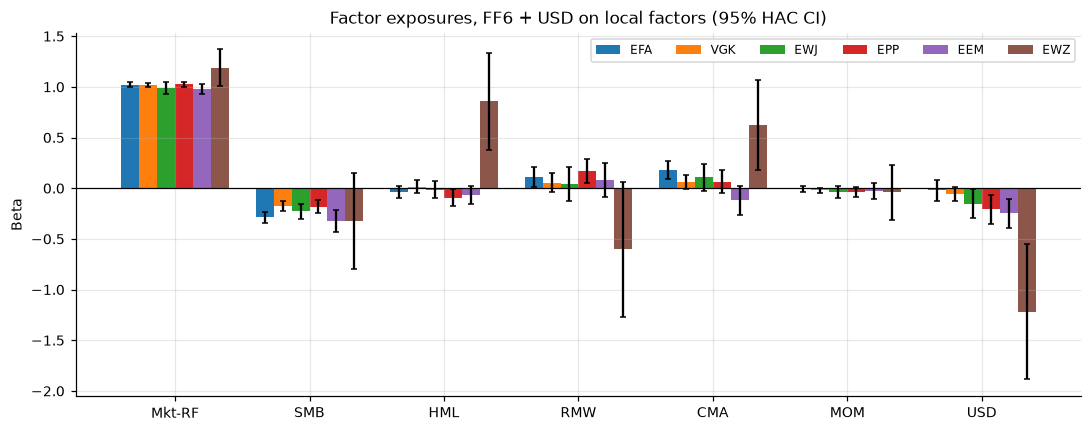

In [6]:
coefs = {t: models.coef_table(r["FF6+USD"]) for t, r in fits.items()}
display(pd.DataFrame({t: c["coef"] for t, c in coefs.items()}).T)
fig = plots.exposure_bars(coefs, "Factor exposures, FF6 + USD on local factors (95% HAC CI)")
save(fig, "02_exposures")

## 6. Global vs local factors (integration vs segmentation)
Same FF6 specification and months; only the factor region changes. If local factors explain
returns much better, the market behaves as if partly **segmented** from global risk pricing.

alpha_ann  alpha_t  beta_mkt  adj_r2  n_months
ETF factors                                                
EFA global      -0.035   -3.361     1.050   0.914   260.000
    local       -0.012   -2.874     1.023   0.980   260.000
VGK global      -0.040   -2.916     1.150   0.896   258.000
    local       -0.004   -1.050     1.017   0.986   258.000
EWJ global      -0.011   -0.694     0.777   0.634   260.000
    local       -0.006   -0.906     0.989   0.895   260.000
EPP global      -0.027   -1.356     1.126   0.772   260.000
    local       -0.007   -1.036     1.024   0.952   260.000
EEM global      -0.009   -0.380     1.063   0.697   260.000
    local       -0.006   -0.673     0.987   0.949   260.000
EWZ global      -0.019   -0.335     1.224   0.439   260.000
    local       -0.038   -0.944     1.173   0.655   260.000

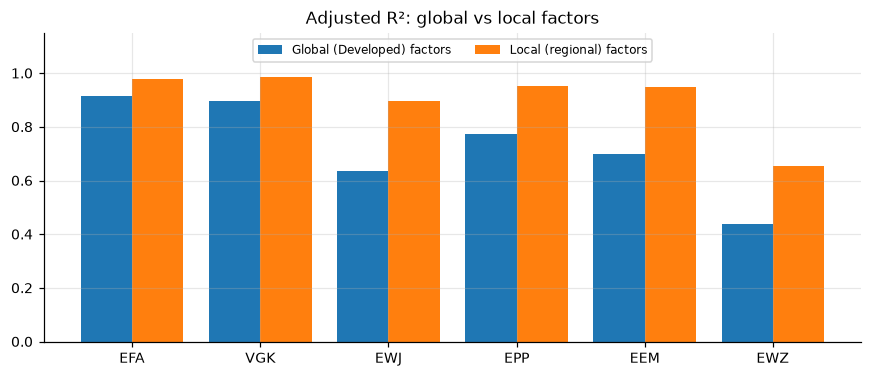

In [7]:
gvl = pd.concat({t: models.global_vs_local(rets[t], factors[region], factors[GLOBAL_REGION])
                 for t, (_, region) in ETFS.items()}, names=["ETF", "factors"])
display(gvl)
fig = plots.global_vs_local_bars(gvl["adj_r2"].unstack())
save(fig, "03_global_vs_local")

## 7. Rolling 36-month exposures
Each point uses only the trailing 36 months, i.e. what an analyst could have measured at that date.

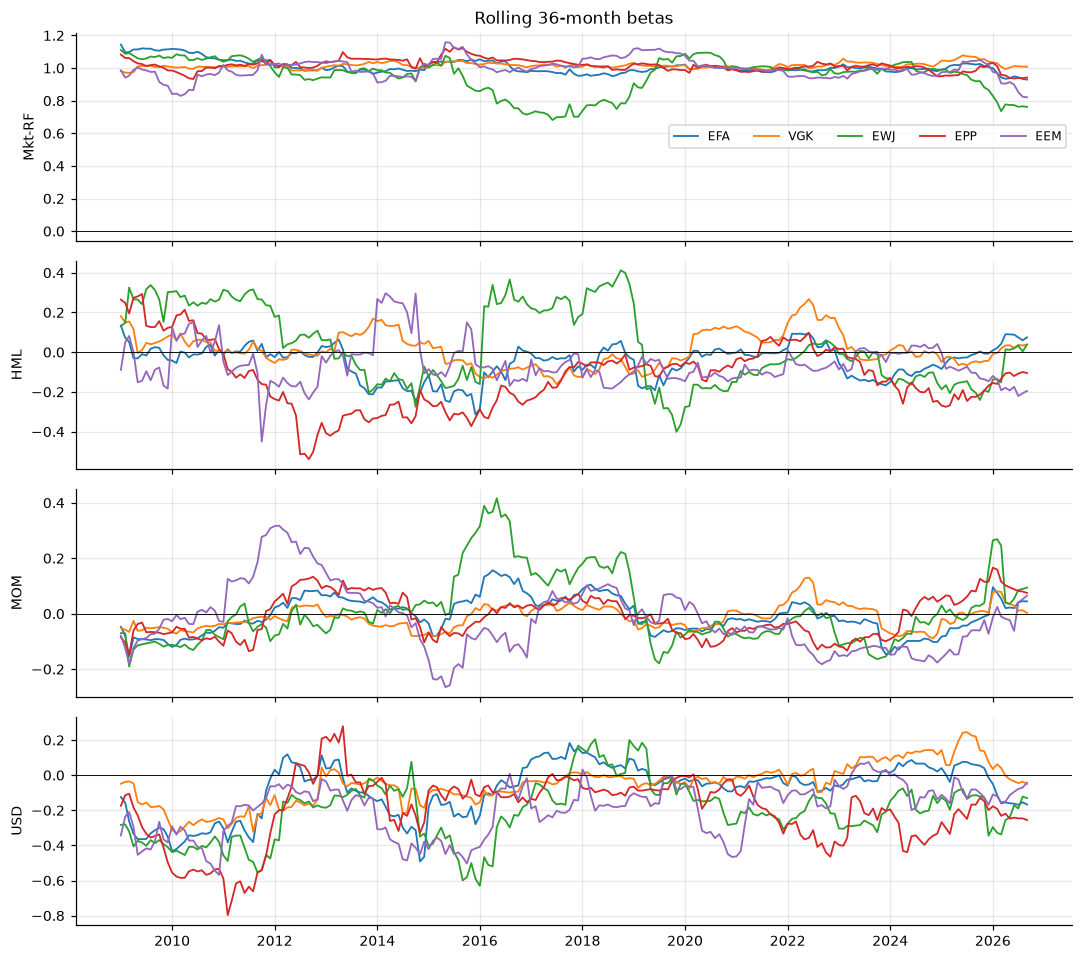

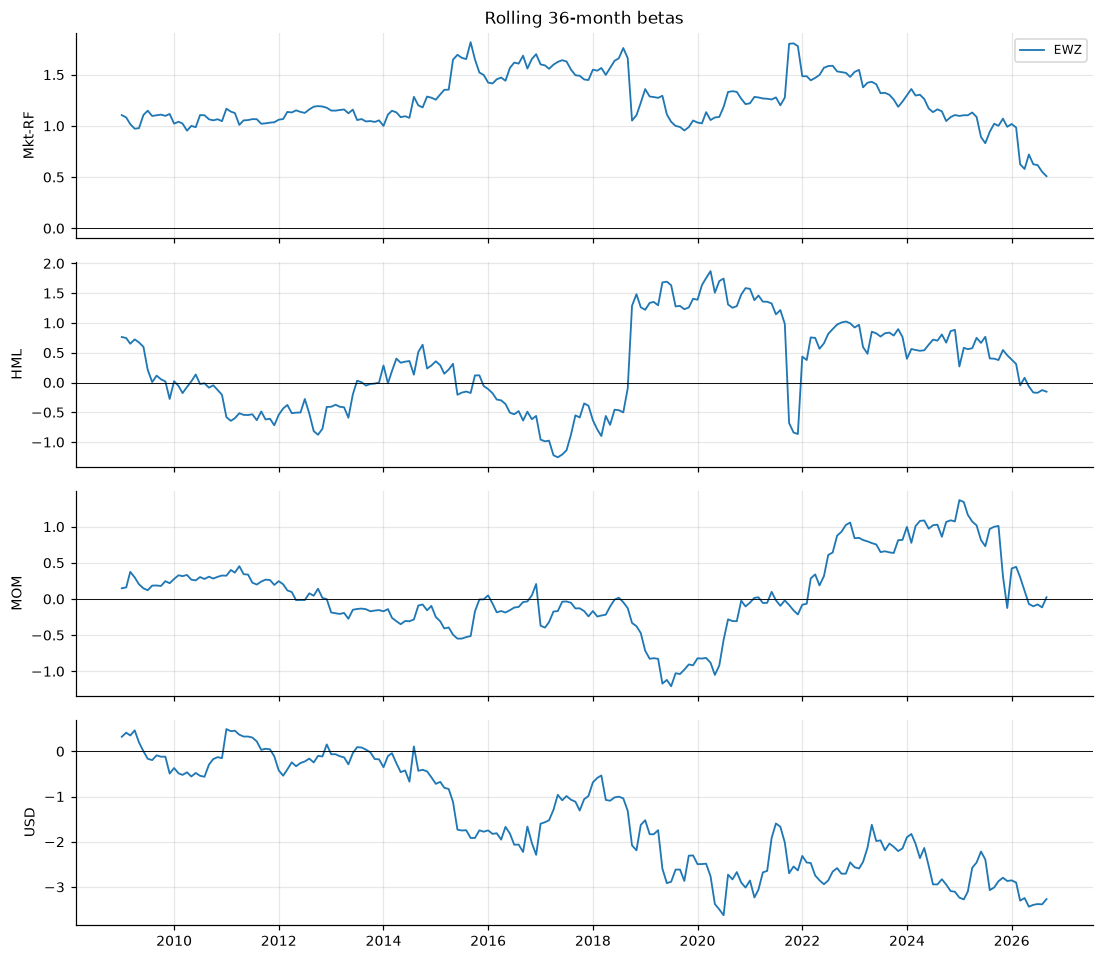

In [8]:
rolling = {t: models.rolling_betas(aligned[t], models.FF6 + ["USD"], WINDOW).dropna() for t in ETFS}
broad = {t: b for t, b in rolling.items() if t not in SINGLE_COUNTRY}
save(plots.rolling_beta_grid(broad, ["Mkt-RF", "HML", "MOM", "USD"], WINDOW), "04_rolling_betas_regional")
# single-country funds vs a broad regional factor set: much noisier, so plotted on their own scale
single = {t: b for t, b in rolling.items() if t in SINGLE_COUNTRY}
save(plots.rolling_beta_grid(single, ["Mkt-RF", "HML", "MOM", "USD"], WINDOW), "04b_rolling_betas_single_country")

## 8. Return attribution
Average annualized excess return split into alpha + Σ beta × factor premium. Components sum to the
ETF's annualized mean excess return (arithmetic, ×12); the in-sample residual averages to zero.

,Mkt-RF,SMB,HML,RMW,CMA,MOM,USD,alpha
EFA,0.059,0.001,-0.001,0.002,0.003,-0.001,0.000,-0.012
VGK,0.063,-0.001,0.000,0.002,0.000,-0.002,-0.000,-0.004
EWJ,0.044,-0.000,-0.001,-0.000,0.003,-0.000,-0.000,-0.007
EPP,0.070,0.003,-0.005,0.007,0.001,-0.003,0.000,-0.007
EEM,0.072,0.002,-0.004,0.003,-0.003,-0.003,-0.000,-0.008
EWZ,0.087,0.002,0.049,-0.019,0.015,-0.004,-0.000,-0.058


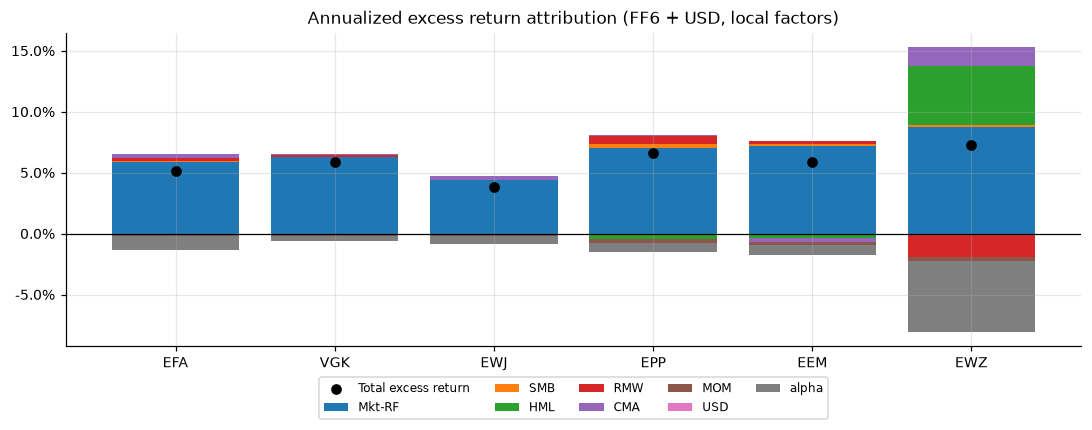

In [9]:
attr = pd.DataFrame({t: models.attribution(fits[t]["FF6+USD"], aligned[t]) for t in ETFS}).T
attr = attr.drop(columns="residual")
assert np.allclose(attr.sum(axis=1), pd.Series({t: aligned[t]["y"].mean() * 12 for t in ETFS}))
display(attr)
fig = plots.attribution_bars(attr, "Annualized excess return attribution (FF6 + USD, local factors)")
save(fig, "05_attribution")

## 9. Residual diagnostics
- **Fitted vs realized**: how close points lie to the 45° line.
- **Cumulative alpha + residual**: a steady downward drift is a cost the factors do not capture
  (expense ratio, dividend withholding tax, index differences).
- **Residual autocorrelation**: negative lag-1 autocorrelation means a one-day timing mismatch (ETFs
  are priced at the New York close; local factors at local market closes) that reverses next month.
  A lagged market term tests the alternative explanation of slow price adjustment.

,resid_ac1,resid_ac2,lagged_mkt_beta,lagged_mkt_t
EFA,-0.358,-0.026,0.015,1.106
VGK,-0.356,0.012,-0.002,-0.272
EWJ,-0.410,-0.061,0.003,0.077
EPP,-0.274,-0.074,-0.007,-0.275
EEM,-0.322,-0.137,-0.013,-0.630
EWZ,-0.107,-0.075,0.024,0.371


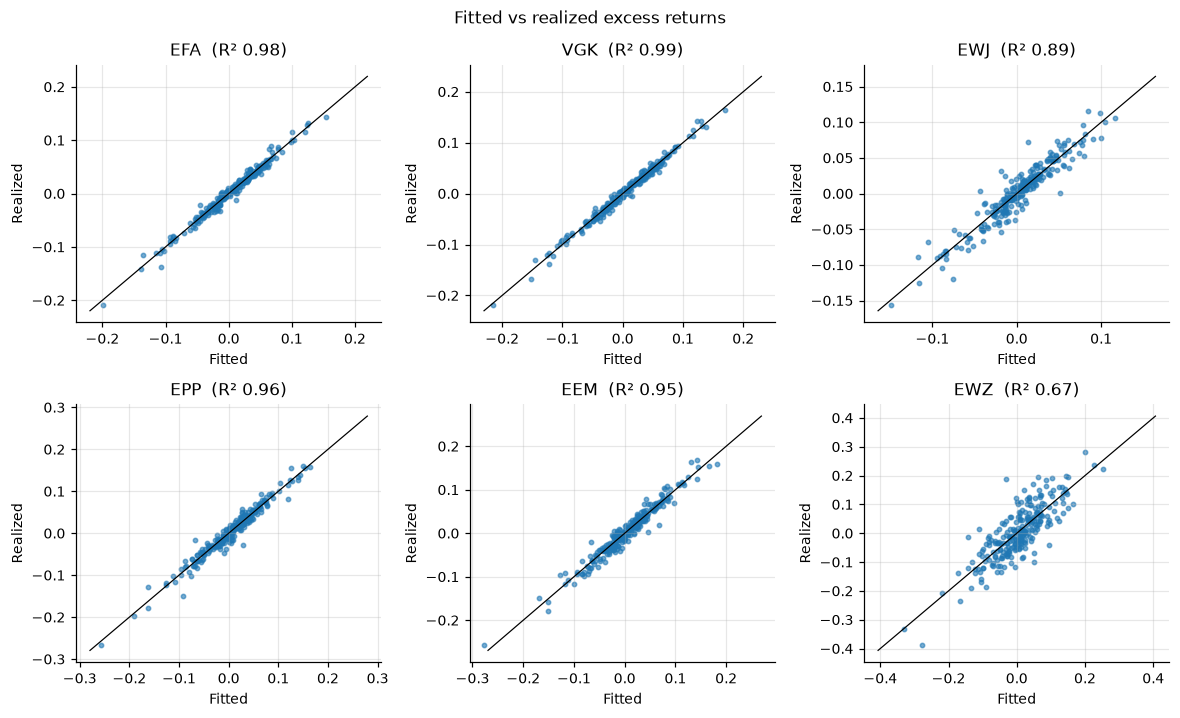

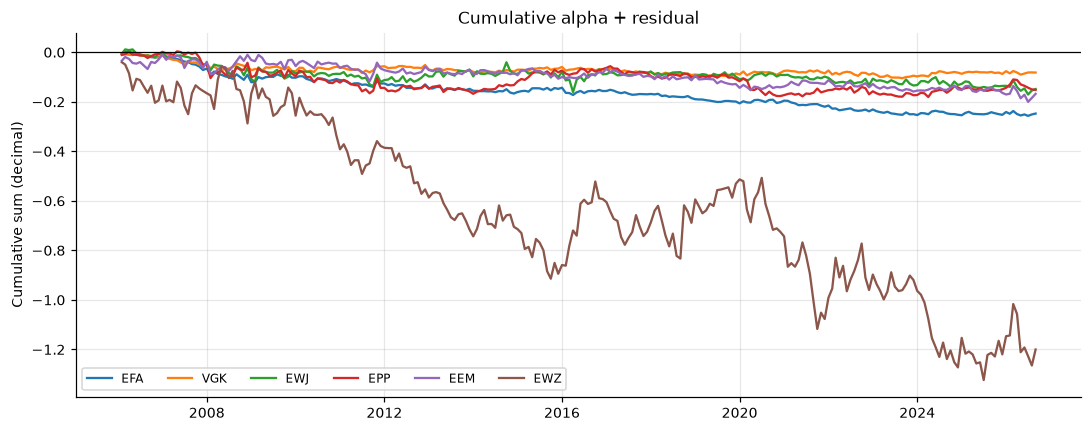

In [10]:
best = {t: (fits[t]["FF6+USD"], aligned[t]) for t in ETFS}
save(plots.fitted_vs_realized(best), "06_fitted_vs_realized")
save(plots.cumulative_residuals(best), "07_cumulative_residuals")

rows = {}
for t in ETFS:
    res, d = best[t]
    lagged = d.assign(Mkt_lag=d["Mkt-RF"].shift(1)).dropna()
    r_lag = models.fit(lagged, models.FF6 + ["USD", "Mkt_lag"])
    rows[t] = {"resid_ac1": res.resid.autocorr(1), "resid_ac2": res.resid.autocorr(2),
               "lagged_mkt_beta": r_lag.params["Mkt_lag"], "lagged_mkt_t": r_lag.tvalues["Mkt_lag"]}
diag = pd.DataFrame(rows).T
display(diag)

## 10. Quarterly-return robustness
Compare monthly and quarterly **local FF6 + USD** regressions over the same complete calendar
quarters; incomplete quarters and quarters with missing inputs are excluded from both fits.

- Compound ETF total returns, RF, and total market returns separately, then subtract quarterly RF
  from ETF and market returns. Compound the raw USD index changes before re-orthogonalizing USD
  against the market separately at each frequency on the matched sample.
- Sum monthly SMB/HML/RMW/CMA/MOM spreads as fixed-notional long-short payoffs. Compounded
  underlying long/short leg returns cannot be recovered from the monthly spreads alone.
- Annualize alpha arithmetically by ×12 (monthly) or ×4 (quarterly); both fits use Newey–West errors.
  Ljung–Box tests cover one year: 12 monthly lags or 4 quarterly lags. Lag-1 correlations measure
  different horizons (one month versus one quarter).

The table checks whether coarser sampling reduces the timing reversal; a lower residual correlation
does not establish its cause, and quarterly aggregation need not eliminate it. These descriptive
fits also differ through aggregation conventions and the smaller quarterly sample.

In [11]:
quarterly_robustness = pd.concat({
    t: models.quarterly_robustness(rets[t], factors[region], usd)
    for t, (_, region) in ETFS.items()
}, names=["ETF", "frequency"])
with pd.option_context("display.max_columns", None):
    display(quarterly_robustness)

start      end  n_obs  alpha_ann  alpha_t  beta_mkt  \
ETF frequency                                                          
EFA monthly    2006-04  2026-09    246     -0.012   -2.831     1.022   
    quarterly   2006Q2   2026Q3     82     -0.017   -4.863     1.033   
VGK monthly    2006-04  2026-09    246     -0.003   -1.009     1.016   
    quarterly   2006Q2   2026Q3     82     -0.005   -1.296     1.018   
EWJ monthly    2006-04  2026-09    246     -0.008   -1.161     0.988   
    quarterly   2006Q2   2026Q3     82     -0.008   -1.977     1.002   
EPP monthly    2006-04  2026-09    246     -0.007   -0.856     1.024   
    quarterly   2006Q2   2026Q3     82     -0.027   -3.535     1.033   
EEM monthly    2006-04  2026-09    246     -0.006   -0.726     0.977   
    quarterly   2006Q2   2026Q3     82     -0.017   -2.170     0.994   
EWZ monthly    2006-04  2026-09    246     -0.055   -1.341     1.188   
    quarterly   2006Q2   2026Q3     82     -0.017   -0.407     1.085   

               beta_usd  adj_r2  resid_ac1  hac_lags  ljung_box_lags  \
ETF frequency                                                          
EFA monthly      -0.025   0.980     -0.353         4              12   
    quarterly     0.084   0.993     -0.311         3               4   
VGK monthly      -0.055   0.986     -0.358         4              12   
    quarterly    -0.017   0.993     -0.326         3               4   
EWJ monthly      -0.159   0.892     -0.407         4              12   
    quarterly    -0.085   0.967     -0.329         3               4   
EPP monthly      -0.207   0.954     -0.275         4              12   
    quarterly    -0.009   0.984     -0.243         3               4   
EEM monthly      -0.246   0.952     -0.315         4              12   
    quarterly    -0.111   0.976     -0.272         3               4   
EWZ monthly      -1.214   0.665     -0.108         4              12   
    quarterly    -1.451   0.743     -0.200         3               4   

               ljung_box_p  
ETF frequency               
EFA monthly          0.000  
    quarterly        0.037  
VGK monthly          0.000  
    quarterly        0.005  
EWJ monthly          0.000  
    quarterly        0.011  
EPP monthly          0.000  
    quarterly        0.224  
EEM monthly          0.000  
    quarterly        0.002  
EWZ monthly          0.567  
    quarterly        0.128

## 11. Stability: did exposures change?
HAC Wald test that alpha and all betas are equal before and after the split month (Chow-type test).

In [12]:
stab_rows, stab_tables = {}, {}
for t in ETFS:
    table, stat, p = models.stability_test(aligned[t], models.FF6 + ["USD"], SPLIT)
    stab_tables[t] = table
    stab_rows[t] = {"wald_chi2": stat, "p_value": p,
                    "mkt_beta_pre": table.loc["Mkt-RF", "pre"], "mkt_beta_post": table.loc["Mkt-RF", "post"],
                    "usd_beta_pre": table.loc["USD", "pre"], "usd_beta_post": table.loc["USD", "post"]}
stability = pd.DataFrame(stab_rows).T
display(stability)

,wald_chi2,p_value,mkt_beta_pre,mkt_beta_post,usd_beta_pre,usd_beta_post
EFA,10.480,0.233,1.053,0.990,-0.050,0.006
VGK,18.514,0.018,1.013,1.019,-0.082,-0.005
EWJ,13.566,0.094,1.044,0.928,-0.244,-0.001
EPP,17.416,0.026,1.052,0.991,-0.236,-0.176
EEM,19.679,0.012,0.962,0.983,-0.337,-0.125
EWZ,33.810,0.000,1.095,1.185,-0.463,-2.174


## 12. Export tables

In [13]:
summary.to_csv(TAB_DIR / "model_summary.csv")
pd.concat(coefs, names=["ETF", "term"]).to_csv(TAB_DIR / "coefficients_ff6_usd.csv")
gvl.to_csv(TAB_DIR / "global_vs_local.csv")
attr.to_csv(TAB_DIR / "attribution.csv")
diag.to_csv(TAB_DIR / "residual_diagnostics.csv")
stability.to_csv(TAB_DIR / "stability.csv")
quarterly_robustness.to_csv(TAB_DIR / "quarterly_robustness.csv")
print("Saved tables to", TAB_DIR, "and figures to", FIG_DIR)

Saved tables to /Users/a3357/Desktop/prjject/reports/tables and figures to /Users/a3357/Desktop/prjject/reports/figures


## 13. Limitations
- French factors are built from Bloomberg stock data and are not the MSCI indices the ETFs track
  (e.g. `Developed_ex_US` includes Canada, MSCI EAFE does not). Part of each alpha is index mismatch.
- ETF returns are net of fees and foreign dividend withholding taxes; factor returns are not.
- The USD factor is a non-traded index change, so its coefficient is a sensitivity, not a priced premium.
- Survivorship is not an issue for the fixed ETF list, but the list itself was chosen today.
- Alphas and betas are conditional on the model and the 2006–2026 sample.